# 6. Pathways and therapy

*Page 6 of 7.* [previous: 5. Methylation versus expression](https://robinson-vidva.github.io/mb-methylation-xai/05_methylation_vs_expression.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 7. Conclusions](https://robinson-vidva.github.io/mb-methylation-xai/07_conclusions.html)

## 1. Pathways

A single gene rarely explains a tumour. Pathway enrichment asks whether the concordant genes of a
subgroup cluster in a known biological process more often than chance. g:Profiler was queried with the
concordant genes per subgroup against a custom background of all genes that had both measurements,
with GO biological process, KEGG and Reactome as sources. Using the tested genes as background is
important: otherwise every list of brain tumour genes looks enriched for brain development.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

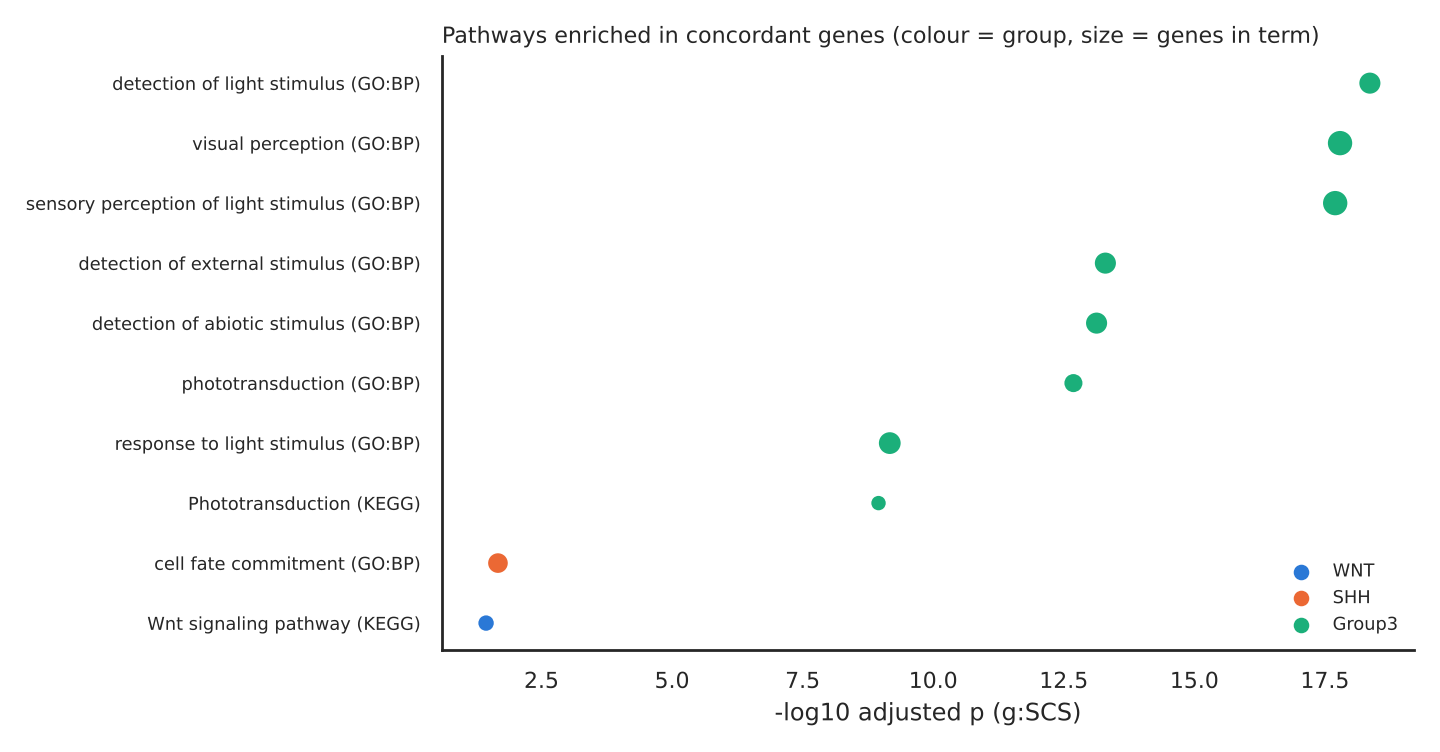

,query,source,name,p_value,intersection_size,term_size
0,Group3,GO:BP,detection of light stimulus,4.350278e-19,15,58
1,Group3,GO:BP,visual perception,1.621626e-18,20,191
2,Group3,GO:BP,sensory perception of light stimulus,2.008513e-18,20,193
3,Group3,GO:BP,detection of external stimulus,5.045791e-14,15,119
4,Group3,GO:BP,detection of abiotic stimulus,7.438510e-14,15,122
5,Group3,GO:BP,phototransduction,2.064502e-13,11,39
46,SHH,GO:BP,cell fate commitment,2.153036e-02,13,273
47,WNT,KEGG,Wnt signaling pathway,3.636497e-02,8,165


In [2]:
import os
if os.path.exists(FIG / 'pathway_enrichment.png'):
    display(Image(FIG / 'pathway_enrichment.png'))
enr = pd.read_csv(TAB / 'pathway_enrichment_concordant_genes.csv')
enr.groupby('query').head(6)[['query', 'source', 'name', 'p_value', 'intersection_size', 'term_size']]

Group 3 is dominated by a photoreceptor program: detection of light stimulus, visual perception,
phototransduction, with NRL, RCVRN, AIPL1, GNAT1 and IMPG2 among the genes. A photoreceptor identity
driven by the transcription factors NRL and CRX is a known and targetable feature of Group 3
medulloblastoma (Garancher et al. 2018). The analysis recovers it from methylation and expression
without being told. WNT returns the KEGG Wnt signalling pathway, the pathway that defines the
subgroup. SHH returns cell fate commitment. Group 4 returns no significant term, consistent with
Group 4 being the least understood subgroup.

## 2. From genes to drugs

Why methylation matters for therapy: a promoter that is hypomethylated in one subgroup switches a gene
on in that subgroup only. If the gene product can be blocked by a drug, the drug would act on those
tumours and spare the others. This is the logic behind subgroup-specific therapy. The reverse case,
a gene silenced by hypermethylation, can in principle be reactivated by demethylating agents such as
decitabine, which are approved in leukaemia.

The **Open Targets Platform** collects, for every human gene, whether an approved drug or a clinical
compound exists against its protein (**tractability**), the drugs and their highest clinical stage,
and an evidence score linking the gene to each disease. Every concordant gene and every curated
driver gene was queried through its public API. Genes were placed in four tiers: approved drug,
clinical compound, druggable (a binding pocket or a druggable protein family, but no compound yet),
or no tractability data.

This is hypothesis generation. A drug against a gene that is on in a subgroup is a lead to read about,
not a treatment. Most of the drugs below were developed for other diseases.

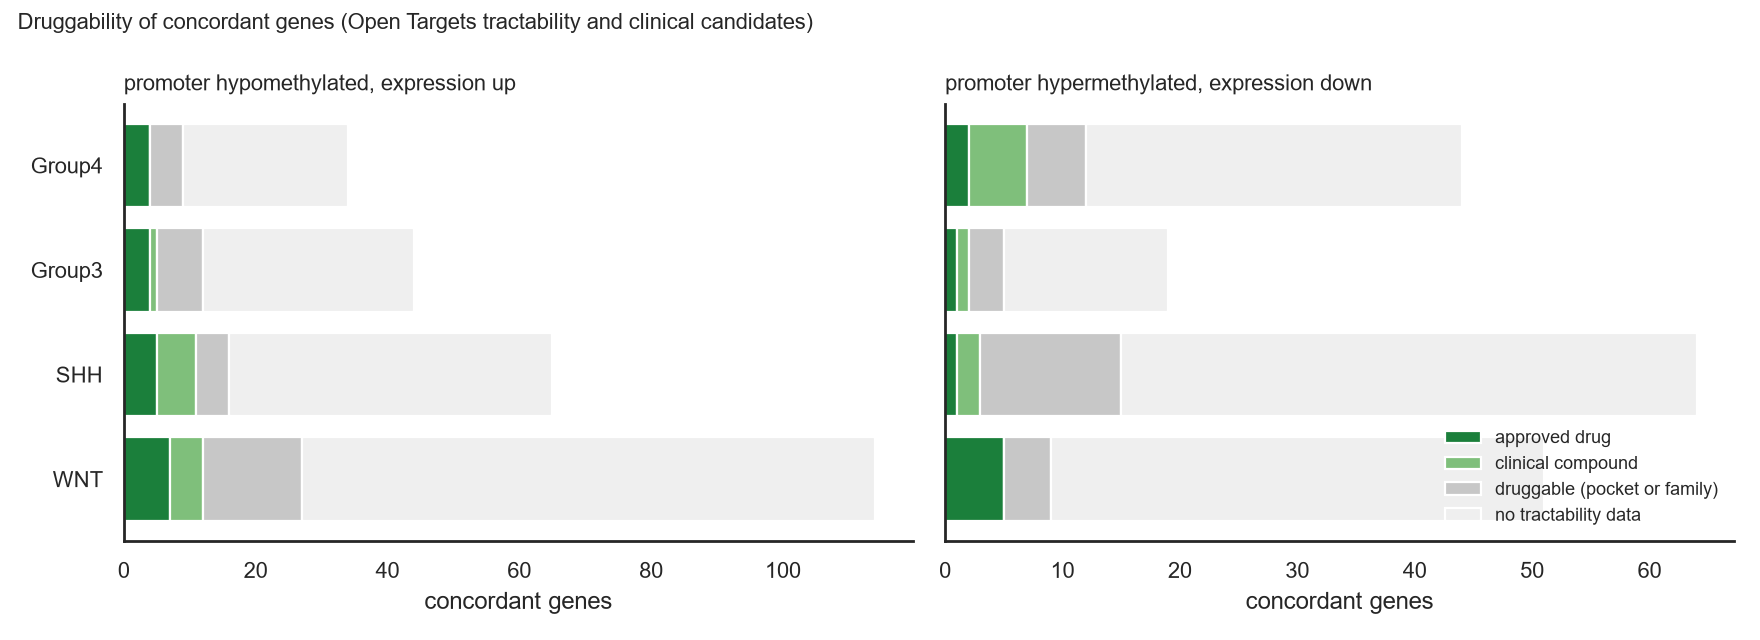

,WNT,SHH,Group3,Group4
no tractability data,129,98,46,57
druggable (pocket or family),19,17,10,10
approved drug,12,6,5,6
clinical compound,5,8,2,5


In [3]:
display(Image(FIG / 'therapy_druggability.png'))
summ = json.load(open(TAB / 'therapy_summary.json'))
pd.DataFrame(summ['per_group_tier_counts']).fillna(0).astype(int)

In [4]:
cand = pd.read_csv(TAB / 'therapy_candidates.csv')
cand = cand[cand['direction'].str.contains('expression up')]
cand.sort_values(['group', 'druggability_tier'])[['group', 'gene', 'druggability_tier', 'highest_clinical_stage', 'mb_association_score', 'example_drugs']].reset_index(drop=True)

,group,gene,druggability_tier,highest_clinical_stage,mb_association_score,example_drugs
0,Group3,CACNA1S,approved drug,APPROVAL,0.0015,AMLODIPINE BENZOATE (APPROVAL; hypertensive disorder); MANIDIPINE 6300 (APPROVAL; aort...
1,Group3,CACNA2D4,approved drug,WITHDRAWAL,0.0000,"TERODILINE (WITHDRAWAL; Polyuria, Urinary incontinence); GABAPENTIN (PHASE_4; Addictiv..."
2,Group3,CACNG5,approved drug,PHASE_3,0.0000,IMAGABALIN (PHASE_3; generalized anxiety disorder); PREGABALIN (WITHDRAWAL; Arthralgia...
3,Group3,PDE6H,approved drug,PHASE_4,0.0000,"PENTOXIFYLLINE (PHASE_4; AIDS, Abdominal pain); DIPYRIDAMOLE (PHASE_4; COVID-19, HIV i..."
4,Group3,IGF1,clinical compound,PHASE_2,0.1023,"XENTUZUMAB (PHASE_2; breast cancer, desmoid tumor); DUSIGITUMAB (PHASE_2; breast cance..."
5,Group4,CACNA1A,approved drug,PHASE_4,0.0629,"GABAPENTIN (PHASE_4; Addictive alcohol use, Alzheimer disease); BEPRIDIL (APPROVAL; ca..."
6,Group4,SLC6A3,approved drug,PHASE_4,0.0337,"LISDEXAMFETAMINE DIMESYLATE (PHASE_4; Alzheimer disease, Huntington disease); NOMIFENS..."
7,Group4,KCNA5,approved drug,PHASE_4,0.0052,"DALFAMPRIDINE (PHASE_4; Cognitive impairment, Gait disturbance); TEDISAMIL (APPROVAL; ..."
8,Group4,PDE7B,approved drug,PHASE_4,0.0000,"PENTOXIFYLLINE (PHASE_4; AIDS, Abdominal pain); FLAVOXATE (PHASE_4; Polyuria, Urinary ..."
9,SHH,PDE1A,approved drug,PHASE_4,0.0181,"PENTOXIFYLLINE (PHASE_4; AIDS, Abdominal pain); DIPYRIDAMOLE (PHASE_4; COVID-19, HIV i..."


**Reading the result.** Most concordant genes have no drug and no known pocket. The genes that do
have drugs are mostly ion channels, phosphodiesterases and extracellular matrix proteins, with drugs
developed for heart, nerve or fibrotic disease. Only one concordant gene, ZFHX3 in WNT, has an
Open Targets association with medulloblastoma above 0.3. A few leads are worth noting:

- **SYK** and **EPHA3** are switched on in WNT tumours. Both are kinases with clinical inhibitors
  (fostamatinib is approved; KB-004 targets EPHA3 in leukaemia and glioblastoma). WNT tumours already
  have an excellent outcome, so the clinical question there is de-escalation, not new drugs.
- **IGF1** is switched on in Group 3. IGF signalling has clinical antibodies (xentuzumab) and is a
  known growth signal in medulloblastoma models.
- **FZD7**, **FAP**, **LGALS1** and **COL1A2** are switched on in SHH. FZD7 is a Wnt receptor with a
  phase 1 antibody. FAP, LGALS1 and collagens mark the tumour stroma and the SHH subgroup is known to
  carry a desmoplastic stroma. These are markers of the microenvironment, not of the tumour cell.
- **MAPK10** (JNK3), switched on in SHH, has clinical JNK inhibitors.

The curated driver genes tell the complementary story.

In [5]:
drv = pd.read_csv(TAB / 'therapy_driver_genes.csv')
drv[['group', 'driver_gene' if 'driver_gene' in drv.columns else 'gene', 'druggability_tier', 'highest_clinical_stage', 'mb_association_score', 'example_drugs']].rename(columns={'gene': 'driver_gene'})

,group,driver_gene,druggability_tier,highest_clinical_stage,mb_association_score,example_drugs
0,WNT,CTNNB1,clinical compound,PHASE_2,0.7532,"PRI-724 (PHASE_2; acute myeloid leukemia, acute myeloid leukemia by FAB classification)"
1,WNT,DDX3X,druggable (pocket or family),NaN,0.6887,NaN
2,WNT,SMARCA4,druggable (pocket or family),NaN,0.6159,NaN
3,WNT,TP53,clinical compound,PHASE_3,0.5362,TEPRASIRAN (PHASE_3; renal artery disease); SIREMADLIN (PHASE_2; acute myeloid leukemi...
4,WNT,KMT2D,no tractability data,NaN,0.6434,NaN
5,SHH,PTCH1,no tractability data,NaN,0.6735,NaN
6,SHH,SUFU,druggable (pocket or family),NaN,0.8049,NaN
7,SHH,SMO,approved drug,PHASE_4,0.5873,"SONIDEGIB (PHASE_4; acute leukemia, acute myeloid leukemia); TALADEGIB (PHASE_2; cance..."
8,SHH,GLI2,druggable (pocket or family),NaN,0.1949,NaN
9,SHH,MYCN,no tractability data,NaN,0.3013,NaN


Two drivers have approved drugs. **SMO**, the Hedgehog pathway receptor, is the target of vismodegib
and sonidegib, the one subgroup-specific therapy that has reached clinical trials in SHH medulloblastoma.
**CDK6**, amplified in a subset of Group 4, is the target of palbociclib and related inhibitors.
Neither driver is concordant: their promoters do not change. The two layers of the analysis therefore
point at different things. Mutated and amplified drivers are where approved drugs act today.
Methylation-controlled genes mark the lineage program and the microenvironment of each subgroup.
They are candidates for biomarkers and for drug repurposing, and, for Group 3, they recover the
photoreceptor dependency that is already under preclinical study.

*Page 6 of 7.* [previous: 5. Methylation versus expression](https://robinson-vidva.github.io/mb-methylation-xai/05_methylation_vs_expression.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 7. Conclusions](https://robinson-vidva.github.io/mb-methylation-xai/07_conclusions.html)